Generates report figures. Outputs saved to `figures/`.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, roc_auc_score, classification_report
from pathlib import Path

ROOT    = Path(".")
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "font.family":       "serif",
    "font.size":         10,
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "figure.dpi":        150,
})

MODEL_KEYS   = ["logreg", "rf_notxt", "rf_full", "lstm", "selfattlstm_notxt", "selfattlstm_full"]
MODEL_LABELS = ["LR (B0)", "RF-notxt (B1)", "RF-full (B2)",
                "LSTM (A1)", "SelfAtt-notxt (A2)", "SelfAtt-full (M)"]
COLORS  = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]
TICKERS = ["JNJ", "KO", "MRK", "NVDA", "QCOM"]

In [2]:
with open(ROOT / "results" / "metrics.json") as f:
    metrics = json.load(f)

# Per-ticker prediction files: {model}_{ticker}.npz
preds_by_ticker = {
    key: {
        ticker: np.load(
            ROOT / "results" / "predictions" / f"{key}_{ticker}.npz",
            allow_pickle=True,
        )
        for ticker in TICKERS
    }
    for key in MODEL_KEYS
}

def concat_test(key):
    """Concatenate test-set predictions across all tickers for a given model."""
    labels = np.concatenate([preds_by_ticker[key][t]["test_labels"] for t in TICKERS])
    probs  = np.concatenate([preds_by_ticker[key][t]["test_probs"]  for t in TICKERS])
    return labels, probs

features = pd.read_parquet(ROOT / "data" / "processed" / "features.parquet")
print(f"features: {features.shape}  |  tickers: {sorted(features['Ticker'].unique())}")

features: (9325, 23)  |  tickers: ['JNJ', 'KO', 'MRK', 'NVDA', 'QCOM']


## Fig 1 — EDA

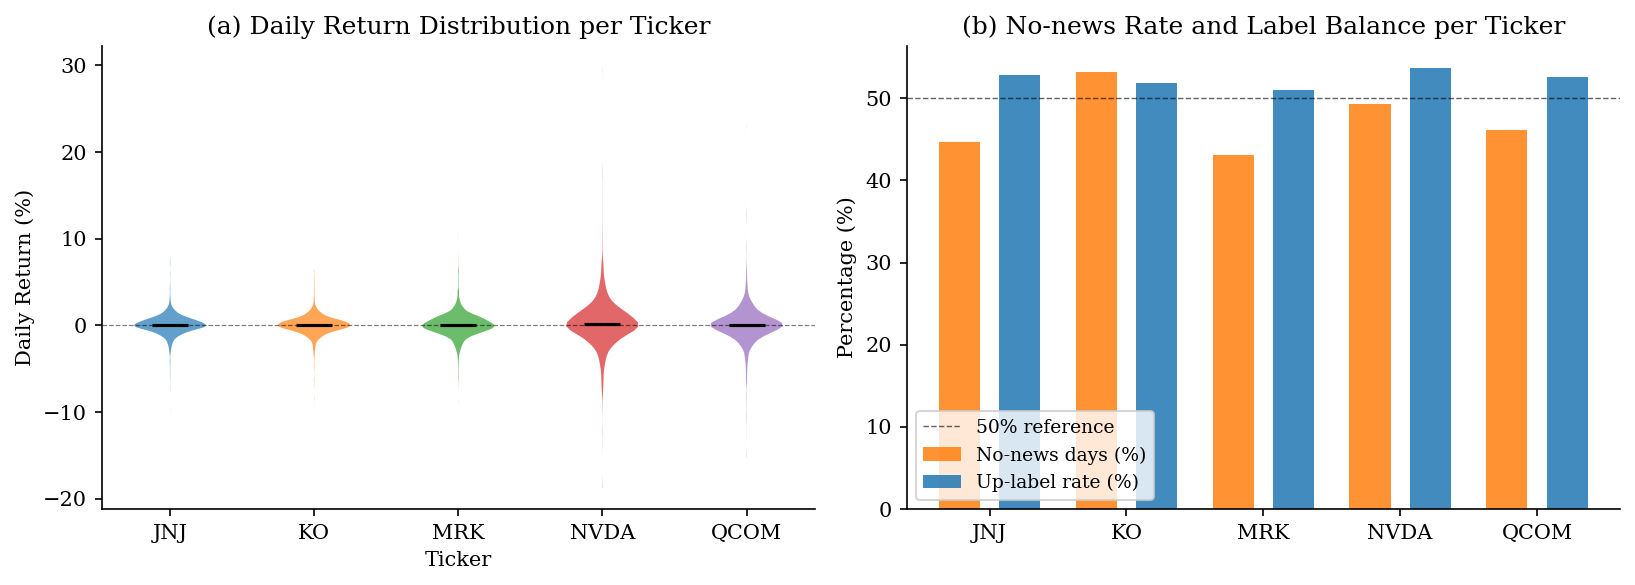

Saved fig1_eda


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# ── (a) Daily return distribution in % ────────────────────────────────────
data_violin = [
    features[features["Ticker"] == t]["return_1d"].dropna().values * 100
    for t in TICKERS
]
parts = axes[0].violinplot(data_violin, positions=range(len(TICKERS)),
                            showmedians=True, showextrema=False)
for i, pc in enumerate(parts["bodies"]):
    pc.set_facecolor(COLORS[i % len(COLORS)])
    pc.set_alpha(0.7)
parts["cmedians"].set_color("black")
parts["cmedians"].set_linewidth(1.5)

axes[0].set_xticks(range(len(TICKERS)))
axes[0].set_xticklabels(TICKERS)
axes[0].set_xlabel("Ticker")
axes[0].set_ylabel("Daily Return (%)")
axes[0].set_title("(a) Daily Return Distribution per Ticker")
axes[0].axhline(0, color="black", linewidth=0.6, linestyle="--", alpha=0.5)

# ── (b) No-news rate and label balance — separated bars ───────────────────
# No-news days are stored as empty string "", not NaN
no_news_pct  = features.groupby("Ticker")["headline"].apply(
    lambda x: (x == "").mean() * 100).reindex(TICKERS).values
label_up_pct = features.groupby("Ticker")["target"].mean().reindex(TICKERS).values * 100

x   = np.arange(len(TICKERS))
w   = 0.30   # bar width
off = 0.22   # center offset; off > w/2 guarantees a visible gap between bars
axes[1].bar(x - off, no_news_pct,  w, label="No-news days (%)",
            color="#ff7f0e", alpha=0.85)
axes[1].bar(x + off, label_up_pct, w, label="Up-label rate (%)",
            color="#1f77b4", alpha=0.85)
axes[1].axhline(50, color="black", linewidth=0.7, linestyle="--",
                alpha=0.6, label="50% reference")
axes[1].set_xticks(x)
axes[1].set_xticklabels(TICKERS)
axes[1].set_ylabel("Percentage (%)")
axes[1].set_title("(b) No-news Rate and Label Balance per Ticker")
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig(FIG_DIR / "fig1_eda.pdf", bbox_inches="tight")
plt.savefig(FIG_DIR / "fig1_eda.png", bbox_inches="tight")
plt.show()
print("Saved fig1_eda")

## Fig 3 — ROC curves and val vs test AUC

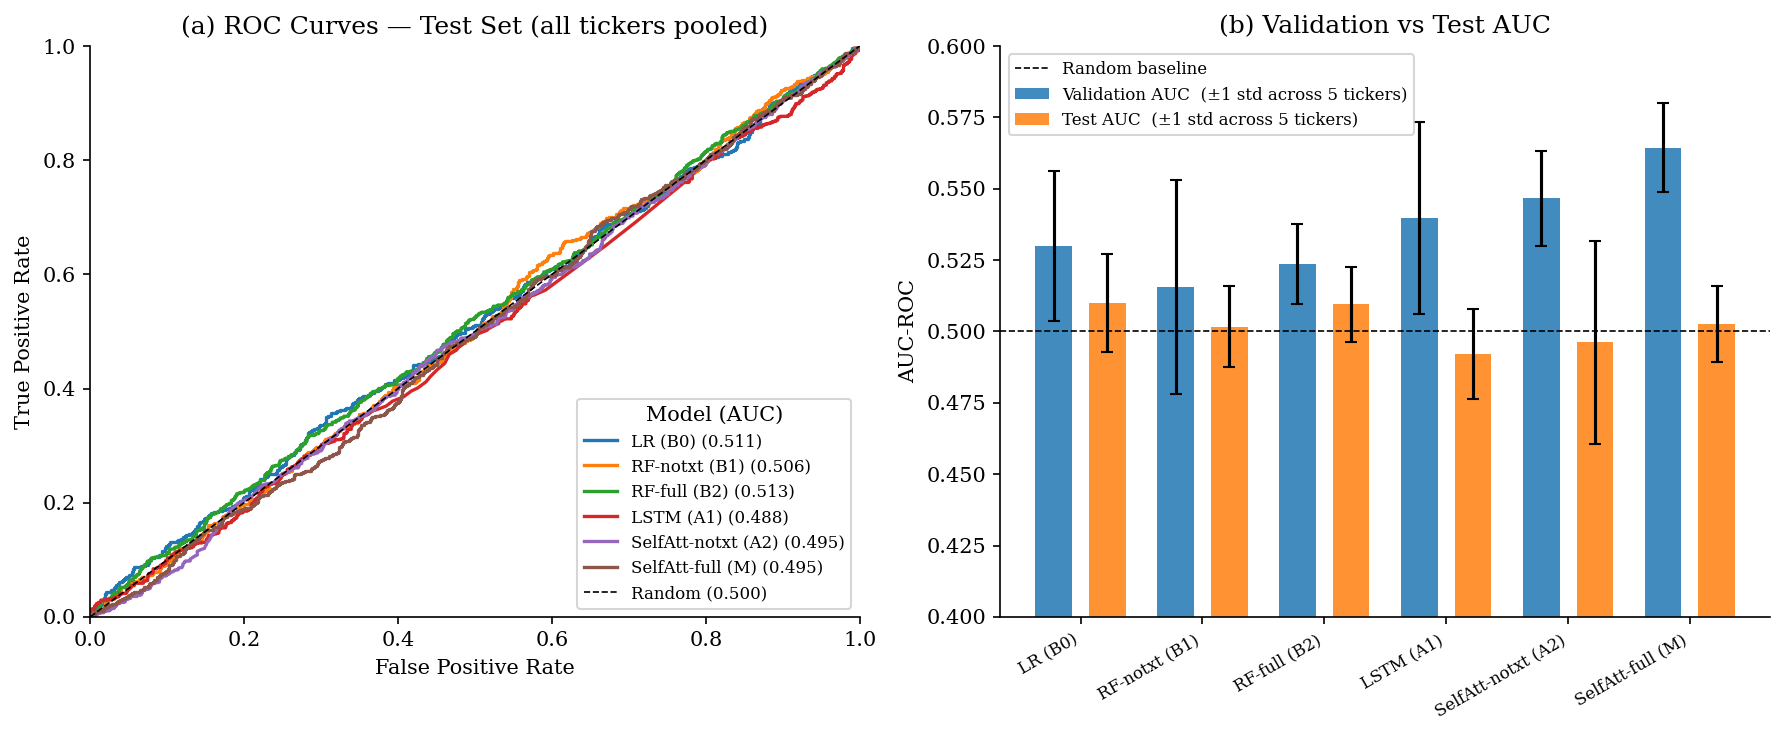

Saved fig3_roc_auc


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ── (a) ROC curves — predictions concatenated across all 5 tickers ────────
for i, (key, label) in enumerate(zip(MODEL_KEYS, MODEL_LABELS)):
    labels, probs = concat_test(key)
    fpr, tpr, _ = roc_curve(labels, probs)
    roc_auc = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, color=COLORS[i], lw=1.6,
                 label=f"{label} ({roc_auc:.3f})")

axes[0].plot([0, 1], [0, 1], "k--", lw=0.8, label="Random (0.500)")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("(a) ROC Curves — Test Set (all tickers pooled)")
axes[0].legend(fontsize=8, loc="lower right", title="Model (AUC)")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)

# ── (b) Val vs Test AUC — error bars = ±1 std across 5 tickers ────────────
agg = metrics["aggregated"]
val_aucs  = [agg[k]["val_auc"]["mean"]  for k in MODEL_KEYS]
test_aucs = [agg[k]["test_auc"]["mean"] for k in MODEL_KEYS]
val_stds  = [agg[k]["val_auc"]["std"]   for k in MODEL_KEYS]
test_stds = [agg[k]["test_auc"]["std"]  for k in MODEL_KEYS]

x   = np.arange(len(MODEL_KEYS))
w   = 0.30
off = 0.22
axes[1].bar(x - off, val_aucs,  w, yerr=val_stds,  capsize=3,
            label="Validation AUC  (±1 std across 5 tickers)",
            color="#1f77b4", alpha=0.85)
axes[1].bar(x + off, test_aucs, w, yerr=test_stds, capsize=3,
            label="Test AUC  (±1 std across 5 tickers)",
            color="#ff7f0e", alpha=0.85)
axes[1].axhline(0.5, color="black", lw=0.8, linestyle="--", label="Random baseline")
axes[1].set_xticks(x)
axes[1].set_xticklabels(MODEL_LABELS, rotation=30, ha="right", fontsize=8)
axes[1].set_ylabel("AUC-ROC")
axes[1].set_title("(b) Validation vs Test AUC")
axes[1].legend(fontsize=8)
axes[1].set_ylim(0.4, 0.6)

plt.tight_layout()
plt.savefig(FIG_DIR / "fig3_roc_auc.pdf", bbox_inches="tight")
plt.savefig(FIG_DIR / "fig3_roc_auc.png", bbox_inches="tight")
plt.show()
print("Saved fig3_roc_auc")

## Fig 4 — Error analysis

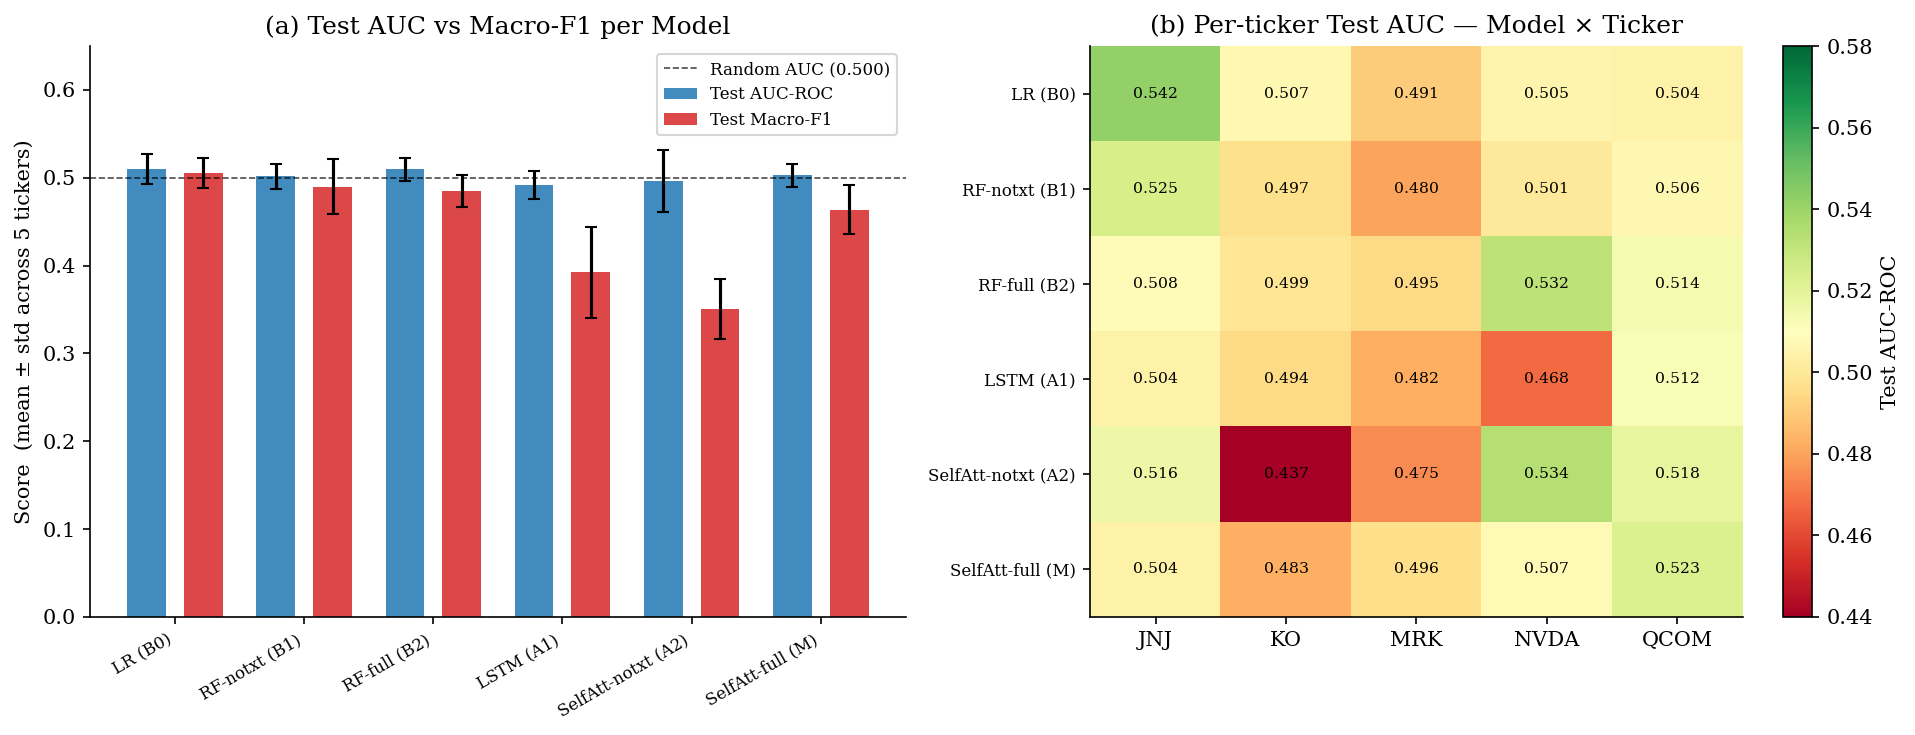

Saved fig4_error_analysis


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ── (a) Test AUC vs Macro-F1 — aggregated across tickers ─────────────────
agg       = metrics["aggregated"]
test_aucs = [agg[k]["test_auc"]["mean"] for k in MODEL_KEYS]
test_f1s  = [agg[k]["test_f1"]["mean"]  for k in MODEL_KEYS]
auc_stds  = [agg[k]["test_auc"]["std"]  for k in MODEL_KEYS]
f1_stds   = [agg[k]["test_f1"]["std"]   for k in MODEL_KEYS]

x   = np.arange(len(MODEL_KEYS))
w   = 0.30
off = 0.22
axes[0].bar(x - off, test_aucs, w, yerr=auc_stds, capsize=3,
            label="Test AUC-ROC",  color="#1f77b4", alpha=0.85)
axes[0].bar(x + off, test_f1s,  w, yerr=f1_stds,  capsize=3,
            label="Test Macro-F1", color="#d62728", alpha=0.85)
axes[0].axhline(0.5, color="black", lw=0.8, linestyle="--", alpha=0.7,
                label="Random AUC (0.500)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(MODEL_LABELS, rotation=30, ha="right", fontsize=8)
axes[0].set_ylabel("Score  (mean ± std across 5 tickers)")
axes[0].set_title("(a) Test AUC vs Macro-F1 per Model")
axes[0].legend(fontsize=8)
axes[0].set_ylim(0.0, 0.65)

# ── (b) Test AUC heatmap — model × ticker ────────────────────────────────
# Each cell = test AUC of that model trained specifically on that ticker
heatmap_data = np.array([
    [
        metrics["per_ticker"][ticker][key]["test_auc"]["mean"]
        for ticker in TICKERS
    ]
    for key in MODEL_KEYS
])  # shape: (n_models, n_tickers)

im = axes[1].imshow(heatmap_data, aspect="auto", cmap="RdYlGn",
                    vmin=0.44, vmax=0.58)
plt.colorbar(im, ax=axes[1], label="Test AUC-ROC")

axes[1].set_xticks(range(len(TICKERS)))
axes[1].set_xticklabels(TICKERS)
axes[1].set_yticks(range(len(MODEL_KEYS)))
axes[1].set_yticklabels(MODEL_LABELS, fontsize=8)
axes[1].set_title("(b) Per-ticker Test AUC — Model × Ticker")

# Annotate cells
for i in range(len(MODEL_KEYS)):
    for j in range(len(TICKERS)):
        val = heatmap_data[i, j]
        axes[1].text(j, i, f"{val:.3f}", ha="center", va="center",
                     fontsize=7.5, color="black")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig4_error_analysis.pdf", bbox_inches="tight")
plt.savefig(FIG_DIR / "fig4_error_analysis.png", bbox_inches="tight")
plt.show()
print("Saved fig4_error_analysis")

## Fig 5 — Self-Attention Weight Heatmap (SelfAtt-LSTM-full)

/Users/OwenChen2/anaconda3/envs/comp0162/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Visualisation ticker: QCOM  (test AUC = 0.5227)
Params: hidden_dim=128  n_heads=1  dropout=0.183
Retrained — best val AUC: 0.5607  (stopped at epoch 10)
Representative sample: QCOM  2019-02-21  label=↑  p=0.565


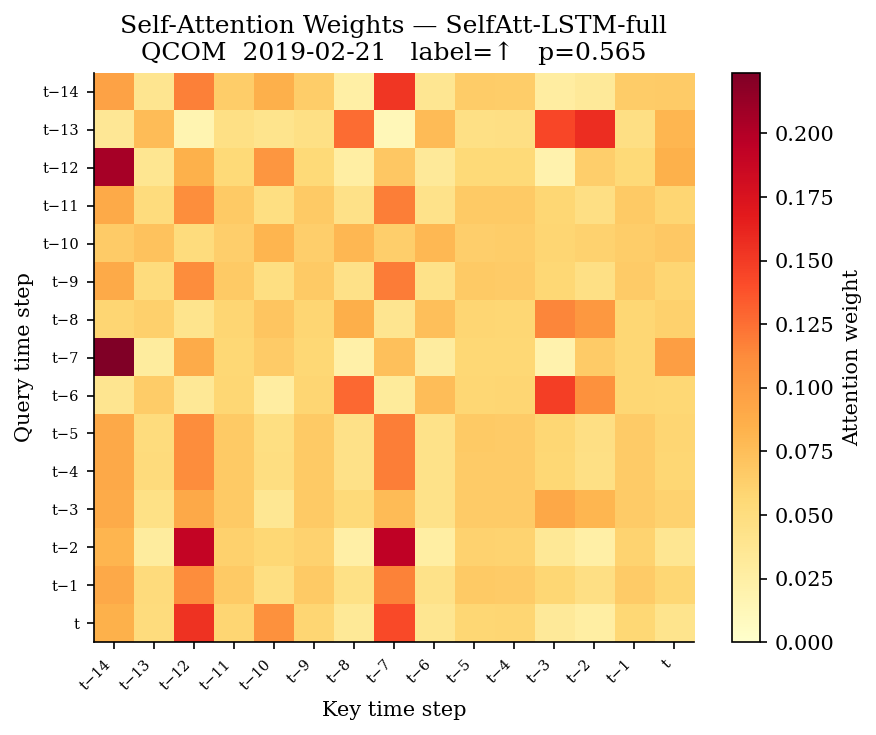

Saved fig5_attention_heatmap


In [6]:
import sys
import torch
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

sys.path.insert(0, str(ROOT / "src"))
from models import SelfAttLSTM, N_FULL_FEATURES
from train import FEATURE_COLS, WINDOW, TRAIN_END, VAL_END

# ── Pick ticker with best test AUC for selfattlstm_full ───────────────────
per_ticker_auc = {
    t: metrics["per_ticker"][t]["selfattlstm_full"]["test_auc"]["mean"]
    for t in TICKERS
}
VIZ_TICKER = max(per_ticker_auc, key=per_ticker_auc.get)
print(f"Visualisation ticker: {VIZ_TICKER}  "
      f"(test AUC = {per_ticker_auc[VIZ_TICKER]:.4f})")

# ── Reload processed data ─────────────────────────────────────────────────
features_df = pd.read_parquet(ROOT / "data" / "processed" / "features.parquet")
emb_pca     = np.load(ROOT / "data" / "processed" / "embeddings_pca.npy")

features_df["date"] = pd.to_datetime(features_df["Date"]).dt.date
ticker_df = features_df[features_df["Ticker"] == VIZ_TICKER].sort_values("date")

train_ticker = ticker_df[ticker_df["date"] <= TRAIN_END]
val_ticker   = ticker_df[(ticker_df["date"] > TRAIN_END) & (ticker_df["date"] <= VAL_END)]
test_ticker  = ticker_df[ticker_df["date"] > VAL_END]

scaler = MinMaxScaler()
scaler.fit(train_ticker[FEATURE_COLS].values)

# ── Device ────────────────────────────────────────────────────────────────
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

# ── Retrieve best params from metrics.json ────────────────────────────────
best_params = metrics["per_ticker"][VIZ_TICKER]["selfattlstm_full"]["best_params"]
hidden_dim  = best_params.get("hidden_dim", 64)
n_heads     = best_params.get("n_heads", 4)
dropout     = best_params.get("lstm_dropout", best_params.get("dropout", 0.2))
lr          = best_params.get("lr", 1e-3)
weight_decay = best_params.get("weight_decay", 1e-5)
batch_size  = best_params.get("batch_size", 32)
grad_clip   = best_params.get("grad_clip", 1.0)
print(f"Params: hidden_dim={hidden_dim}  n_heads={n_heads}  dropout={dropout:.3f}")

# ── Build sliding-window tensors ──────────────────────────────────────────
def build_windows(df):
    grp      = df.sort_values("date")
    orig_idx = grp.index.values
    price    = scaler.transform(grp[FEATURE_COLS].values).astype(np.float32)
    embs     = emb_pca[orig_idx].astype(np.float32)
    tgt      = grp["target"].values.astype(np.float32)
    dates    = grp["date"].values
    X, y, meta = [], [], []
    for i in range(WINDOW - 1, len(grp)):
        sl = slice(i - WINDOW + 1, i + 1)
        X.append(np.concatenate([price[sl], embs[sl]], axis=1))
        y.append(tgt[i])
        meta.append((str(dates[i]), VIZ_TICKER))
    return np.stack(X), np.array(y), meta

X_tr, y_tr, _        = build_windows(train_ticker)
X_va, y_va, _        = build_windows(val_ticker)
X_te, y_te, meta_te  = build_windows(test_ticker)

from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn

def make_tensor_loader(X, y, shuffle):
    ds = TensorDataset(torch.from_numpy(X), torch.from_numpy(y).unsqueeze(1))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

train_loader = make_tensor_loader(X_tr, y_tr, shuffle=True)
val_loader   = make_tensor_loader(X_va, y_va, shuffle=False)

# ── Retrain for 1 seed (fast — single ticker) ────────────────────────────
torch.manual_seed(0)
np.random.seed(0)
model = SelfAttLSTM(input_dim=N_FULL_FEATURES, hidden_dim=hidden_dim,
                    n_heads=n_heads, dropout=dropout).to(device)
n_neg_tr = (y_tr == 0).sum()
n_pos_tr = (y_tr == 1).sum()
pos_weight = torch.tensor([n_neg_tr / n_pos_tr], dtype=torch.float32).to(device)
criterion  = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer  = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

best_val_auc, best_state, patience, wait = 0.0, None, 10, 0
from sklearn.metrics import roc_auc_score as _ras

for epoch in range(100):
    model.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
        optimizer.step()
    model.eval()
    with torch.no_grad():
        va_logits = model(torch.from_numpy(X_va).to(device)).squeeze(1).cpu().numpy()
    va_probs = 1 / (1 + np.exp(-va_logits))
    va_auc = _ras(y_va, va_probs) if len(np.unique(y_va)) > 1 else 0.5
    if va_auc > best_val_auc:
        best_val_auc = va_auc
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        wait = 0
    else:
        wait += 1
    if wait >= patience:
        break

model.load_state_dict(best_state)
model.eval()
print(f"Retrained — best val AUC: {best_val_auc:.4f}  (stopped at epoch {epoch})")

# ── Forward pass on test set to pick most confident correct prediction ────
with torch.no_grad():
    te_logits = model(torch.from_numpy(X_te).to(device)).squeeze(1).cpu().numpy()
te_probs = 1 / (1 + np.exp(-te_logits))
te_preds = (te_probs > 0.5).astype(int)
correct  = te_preds == y_te.astype(int)
conf     = np.where(te_preds == 1, te_probs, 1 - te_probs)
conf[~correct] = -1
best_idx = int(np.argmax(conf))

date_str, ticker_str = meta_te[best_idx]
true_label = int(y_te[best_idx])
pred_prob  = te_probs[best_idx]
print(f"Representative sample: {ticker_str}  {date_str}  "
      f"label={'↑' if true_label else '↓'}  p={pred_prob:.3f}")

# ── Extract attention weights for that sample ─────────────────────────────
x_single = torch.from_numpy(X_te[best_idx : best_idx + 1]).to(device)
with torch.no_grad():
    _ = model(x_single)
attn = model.attn_weights[0].cpu().numpy()   # (T, T)

# ── Plot ──────────────────────────────────────────────────────────────────
T           = attn.shape[0]
tick_labels = [f"t−{T-1-i}" if i < T - 1 else "t" for i in range(T)]

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(attn, aspect="auto", cmap="YlOrRd", vmin=0, vmax=attn.max())
plt.colorbar(im, ax=ax, label="Attention weight")

ax.set_xticks(range(T))
ax.set_xticklabels(tick_labels, rotation=45, ha="right", fontsize=7)
ax.set_yticks(range(T))
ax.set_yticklabels(tick_labels, fontsize=7)
ax.set_xlabel("Key time step")
ax.set_ylabel("Query time step")
ax.set_title(
    f"Self-Attention Weights — SelfAtt-LSTM-full\n"
    f"{ticker_str}  {date_str}   "
    f"label={'↑' if true_label else '↓'}   p={pred_prob:.3f}"
)

plt.tight_layout()
plt.savefig(FIG_DIR / "fig5_attention_heatmap.pdf", bbox_inches="tight")
plt.savefig(FIG_DIR / "fig5_attention_heatmap.png", bbox_inches="tight")
plt.show()
print("Saved fig5_attention_heatmap")

## Summary

In [7]:
saved = sorted(FIG_DIR.glob("*.pdf"))
print(f"{len(saved)} PDF figures in figures/:")
for f in saved:
    print(f"  {f.name}")

5 PDF figures in figures/:
  fig1_eda.pdf
  fig2_architecture.pdf
  fig3_roc_auc.pdf
  fig4_error_analysis.pdf
  fig5_attention_heatmap.pdf
